# Theme Alpha Q8 Signal Live Readiness Practice

Q8 tests near-live execution rules for Theme Alpha candidates:

- fixed twice-monthly calendar signals;
- close signal with next-trading-day execution;
- liquidity, spread, and premium/discount assumptions.

In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q8-signal-live-readiness")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2020-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0
REBALANCE_ANCHOR = "2020-01-02"

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

CORE_ASSETS = (CSI300, NASDAQ, GOLD)
EXPANDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(CORE_ASSETS + EXPANDED_THEME))
SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50
BASE_COST_BPS = 20
THRESHOLD = 0.02
MAX_TRADE = 0.15

CANDIDATES = {
    "Base_Core80_LVT20": {"defense": None, "destination": None},
    "Def200_Cash": {"defense": 200, "destination": "cash"},
    "Def210_Gold": {"defense": 210, "destination": "gold"},
}
SCHEDULES = ("10D", "BIMONTHLY", "M")
EXECUTION_MODES = ("same_close_proxy", "next_close")
FRICTION_MODES = ("base20", "base20_plus_asset", "base20_plus_asset_stress")
AUMS = (1_000_000, 10_000_000, 50_000_000)

WINDOWS = {
    "2021_to_date": ("2021-01-01", None),
    "2021_2022_bear": ("2021-02-18", "2022-10-31"),
    "2022_full": ("2022-01-01", "2022-12-31"),
    "2025_to_date": ("2025-01-01", None),
    "2026_ytd": ("2026-01-01", None),
}

ASSET_EXTRA_FRICTION_BPS = {
    CSI300: 5,
    GOLD: 5,
    DIVIDEND: 5,
    NASDAQ: 20,
    HK_TECH: 20,
    NONFERROUS: 10,
    CHIP: 10,
    COMM: 10,
    ENERGY: 10,
    BROKER: 10,
    HEALTHCARE: 10,
}

print(f"Output dir: {OUTPUT_DIR}")
print(f"End date request: {END}")

Output dir: outputs/theme-alpha-q8-signal-live-readiness
End date request: 2026-06-24


## Data

In [2]:
def download_ohlcv(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    if isinstance(df.columns, pd.MultiIndex):
        df = df.droplevel(1, axis=1)
    return df[["Close", "Volume"]].rename(columns={"Close": symbol, "Volume": f"{symbol}_volume"})

price_parts = []
volume_parts = []
for sym in ALL_SYMBOLS:
    df = download_ohlcv(sym)
    price_parts.append(df[[sym]])
    volume_parts.append(df[[f"{sym}_volume"]].rename(columns={f"{sym}_volume": sym}))

close_raw = pd.concat(price_parts, axis=1).sort_index()
volume_raw = pd.concat(volume_parts, axis=1).sort_index()
value_raw = close_raw * volume_raw

availability = pd.DataFrame([
    {
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "first_date": close_raw[sym].dropna().index.min().date(),
        "last_date": close_raw[sym].dropna().index.max().date(),
        "price_rows": int(close_raw[sym].dropna().shape[0]),
        "volume_rows": int(volume_raw[sym].dropna().shape[0]),
    }
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

close = close_raw.ffill()
volume = volume_raw.fillna(0.0)
value_traded = value_raw.fillna(0.0)
adv20 = value_traded.rolling(20, min_periods=5).mean()
adv60 = value_traded.rolling(60, min_periods=10).mean()
returns = close.pct_change(fill_method=None)

,symbol,name,first_date,last_date,price_rows,volume_rows
0,510300.SS,沪深300ETF,2020-01-02,2026-06-23,1565,1565
1,513100.SS,纳指100ETF,2020-01-02,2026-06-23,1566,1566
2,518880.SS,黄金ETF,2020-01-02,2026-06-23,1565,1565
3,512400.SS,有色金属ETF,2020-01-02,2026-06-23,1565,1565
4,159995.SZ,芯片ETF,2020-01-20,2026-06-23,1547,1547
5,515880.SS,通信ETF,2020-01-02,2026-06-23,1565,1565
6,510880.SS,红利ETF,2020-01-02,2026-06-23,1565,1565
7,159930.SZ,能源ETF,2020-01-02,2026-06-23,1543,1543
8,512880.SS,证券ETF,2020-01-02,2026-06-23,1565,1565
9,513180.SS,恒生科技ETF,2021-05-18,2026-06-23,1233,1233


## Helpers

In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def signal_dates(index, schedule):
    idx = pd.DatetimeIndex(index)
    if schedule == "10D":
        start = idx.searchsorted(pd.Timestamp(REBALANCE_ANCHOR))
        return set(pd.DatetimeIndex(idx[start::10]))
    if schedule == "M":
        monthly = pd.Series(idx, index=idx).resample("ME").last().dropna()
        return set(pd.DatetimeIndex(monthly.values))
    if schedule == "BIMONTHLY":
        dates = []
        months = pd.period_range(idx.min().to_period("M"), idx.max().to_period("M"), freq="M")
        for p in months:
            for day in (10, 25):
                anchor = pd.Timestamp(year=p.year, month=p.month, day=min(day, p.days_in_month))
                pos = idx.searchsorted(anchor)
                if pos < len(idx) and idx[pos].to_period("M") == p:
                    dates.append(idx[pos])
        return set(pd.DatetimeIndex(sorted(set(dates))))
    raise ValueError(schedule)


def enough_history(sym, loc, window):
    if loc < window:
        return False
    hist = close[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def enough_return_history(sym, loc, window):
    if loc < window:
        return False
    hist = returns[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def risk_parity_weight(date, eligible, universe, cap=None):
    loc = close.index.get_loc(date)
    eligible = [sym for sym in eligible if sym in universe and enough_return_history(sym, loc, RP_VOL_WINDOW)]
    if not eligible:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1:loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def low_vol_trend_selector(universe):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(MA_WINDOW, MOM_WINDOW, VOL_WINDOW)
        if loc < warmup:
            return []
        valid = []
        for sym in universe:
            if not enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)):
                continue
            if not enough_return_history(sym, loc, VOL_WINDOW):
                continue
            valid.append(sym)
        if not valid:
            return []
        price = close.iloc[loc][valid]
        ma = close.iloc[loc - MA_WINDOW + 1:loc + 1][valid].mean()
        mom = price / close.iloc[loc - MOM_WINDOW][valid] - 1.0
        vols = returns.iloc[loc - VOL_WINDOW + 1:loc + 1][valid].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(TOP_N).index.tolist()
    return select


def all_assets(universe):
    return lambda _date: list(universe)


def build_signal_weights(universe, selector, allocator, schedule):
    sdates = signal_dates(close.index, schedule)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in sdates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def defend_core_weights(core_weights, ma_window, destination, schedule):
    sdates = signal_dates(close.index, schedule)
    rows = []
    last = normalize_weights({}, CORE_ASSETS)
    for date in close.index:
        if date in sdates:
            loc = close.index.get_loc(date)
            base = core_weights.loc[date, list(CORE_ASSETS) + ["CASH"]].copy()
            for sym in (CSI300, NASDAQ):
                risk_on = enough_history(sym, loc, ma_window) and close.at[date, sym] > close[sym].iloc[loc - ma_window + 1:loc + 1].mean()
                if not risk_on:
                    moved = base[sym]
                    base[sym] = 0.0
                    if destination == "cash":
                        base["CASH"] += moved
                    elif destination == "gold":
                        base[GOLD] += moved
                    else:
                        raise ValueError(destination)
            last = normalize_weights(base.to_dict(), CORE_ASSETS)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    return out[list(CORE_ASSETS) + ["CASH"]]


def expand_weights(weights):
    out = pd.DataFrame(0.0, index=weights.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for col in weights.columns:
        if col in out.columns:
            out[col] = weights[col]
    return out


def combine_weights(sleeves):
    out = pd.DataFrame(0.0, index=close.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for allocation, weights in sleeves:
        out += allocation * expand_weights(weights).reindex(close.index).ffill().fillna(0.0)
    total = out[list(ALL_SYMBOLS)].sum(axis=1) + out["CASH"]
    return out.div(total.replace(0, np.nan), axis=0).fillna(0.0)


def apply_execution_timing(target_weights, schedule, execution_mode, threshold=THRESHOLD, max_trade=MAX_TRADE):
    cols = list(ALL_SYMBOLS) + ["CASH"]
    sdates = signal_dates(close.index, schedule)
    idx = close.index
    executed_rows = []
    current = pd.Series(0.0, index=cols)
    current["CASH"] = 1.0
    pending = None
    for i, date in enumerate(idx):
        # Execute pending trade at this close; weights affect returns from next row via shift(1).
        if pending is not None and pending["execute_date"] == date:
            desired = pending["target"]
            turnover = 0.5 * (desired - current).abs().sum()
            if turnover >= threshold - 1e-12:
                asset_cols = list(ALL_SYMBOLS)
                delta = (desired[asset_cols] - current[asset_cols]).clip(lower=-max_trade, upper=max_trade)
                new_assets = (current[asset_cols] + delta).clip(lower=0.0)
                asset_sum = new_assets.sum()
                if asset_sum > 1.0:
                    new_assets = new_assets / asset_sum
                    cash = 0.0
                else:
                    cash = 1.0 - asset_sum
                current = pd.concat([new_assets, pd.Series({"CASH": cash})]).reindex(cols).fillna(0.0)
            pending = None
        if date in sdates:
            desired = target_weights.loc[date, cols].copy()
            if execution_mode == "same_close_proxy":
                execute_idx = i
            elif execution_mode == "next_close":
                execute_idx = min(i + 1, len(idx) - 1)
            else:
                raise ValueError(execution_mode)
            pending = {"execute_date": idx[execute_idx], "target": desired}
            if execute_idx == i:
                # Same-close proxy executes immediately at this close.
                desired = pending["target"]
                turnover = 0.5 * (desired - current).abs().sum()
                if turnover >= threshold - 1e-12:
                    asset_cols = list(ALL_SYMBOLS)
                    delta = (desired[asset_cols] - current[asset_cols]).clip(lower=-max_trade, upper=max_trade)
                    new_assets = (current[asset_cols] + delta).clip(lower=0.0)
                    asset_sum = new_assets.sum()
                    current = pd.concat([new_assets, pd.Series({"CASH": max(0.0, 1.0 - asset_sum)})]).reindex(cols).fillna(0.0)
                    if current[asset_cols].sum() > 1.0:
                        current[asset_cols] = current[asset_cols] / current[asset_cols].sum()
                        current["CASH"] = 0.0
                pending = None
        executed_rows.append(current.to_dict())
    return pd.DataFrame(executed_rows, index=idx, columns=cols)


def turnover_by_asset(weights):
    prev = weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    return (weights[list(ALL_SYMBOLS)] - prev).abs().fillna(0.0)


def friction_cost_series(weights, mode):
    asset_turnover = turnover_by_asset(weights)
    cost_bps = pd.Series(BASE_COST_BPS, index=ALL_SYMBOLS, dtype=float)
    if mode in ("base20_plus_asset", "base20_plus_asset_stress"):
        mult = 1.0 if mode == "base20_plus_asset" else 2.0
        extra = pd.Series({sym: ASSET_EXTRA_FRICTION_BPS[sym] * mult for sym in ALL_SYMBOLS})
        cost_bps = cost_bps + extra
    return (asset_turnover * (cost_bps / 10000.0)).sum(axis=1)


def backtest(name, weights, friction_mode):
    asset_weights = weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(ALL_SYMBOLS)]).sum(axis=1, min_count=1).fillna(0.0)
    costs = friction_cost_series(weights, friction_mode)
    net = gross - costs
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {"name": name, "weights": weights, "returns": net, "gross_returns": gross, "costs": costs, "nav": nav}

## Build Portfolios

In [4]:
targets = {}
for schedule in SCHEDULES:
    core = build_signal_weights(CORE_ASSETS, all_assets(CORE_ASSETS), lambda d, e: risk_parity_weight(d, e, CORE_ASSETS, None), schedule)
    lvt = build_signal_weights(EXPANDED_THEME, low_vol_trend_selector(EXPANDED_THEME), lambda d, e: risk_parity_weight(d, e, EXPANDED_THEME, CAP), schedule)
    for candidate, cfg in CANDIDATES.items():
        if cfg["defense"] is None:
            core_used = core
        else:
            core_used = defend_core_weights(core, cfg["defense"], cfg["destination"], schedule)
        targets[(candidate, schedule)] = combine_weights([(0.80, core_used), (0.20, lvt)])

latest_rows = []
for (candidate, schedule), weights in targets.items():
    latest_rows.append({"candidate": candidate, "schedule": schedule, **{SYMBOL_NAMES.get(c, c): weights[c].iloc[-1] for c in ALL_SYMBOLS}, "现金": weights["CASH"].iloc[-1]})
latest_targets = pd.DataFrame(latest_rows)
latest_targets.to_csv(OUTPUT_DIR / "latest_target_weights.csv", index=False, encoding="utf-8-sig")
display(latest_targets.round(4))

portfolio_records = []
portfolios = {}
for candidate, schedule, execution_mode, friction_mode in product(CANDIDATES.keys(), SCHEDULES, EXECUTION_MODES, FRICTION_MODES):
    target = targets[(candidate, schedule)]
    executed = apply_execution_timing(target, schedule, execution_mode)
    name = f"{candidate}_{schedule}_{execution_mode}_{friction_mode}"
    portfolios[name] = backtest(name, executed, friction_mode)
    portfolio_records.append({
        "name": name,
        "candidate": candidate,
        "schedule": schedule,
        "execution_mode": execution_mode,
        "friction_mode": friction_mode,
    })
portfolio_index = pd.DataFrame(portfolio_records)
portfolio_index.to_csv(OUTPUT_DIR / "portfolio_index.csv", index=False, encoding="utf-8-sig")
print(f"Built {len(portfolios)} portfolios")

,candidate,schedule,沪深300ETF,纳指100ETF,黄金ETF,有色金属ETF,芯片ETF,通信ETF,红利ETF,能源ETF,证券ETF,恒生科技ETF,医疗ETF,现金
0,Base_Core80_LVT20,10D,0.3676,0.2610,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0000,0.0,0.0,0.0
1,Def200_Cash,10D,0.3676,0.2610,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0000,0.0,0.0,0.0
2,Def210_Gold,10D,0.3676,0.2610,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0000,0.0,0.0,0.0
3,Base_Core80_LVT20,BIMONTHLY,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0,0.0,0.0000,0.0,0.0,0.0
4,Def200_Cash,BIMONTHLY,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0,0.0,0.0000,0.0,0.0,0.0
5,Def210_Gold,BIMONTHLY,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0,0.0,0.0000,0.0,0.0,0.0
6,Base_Core80_LVT20,M,0.3400,0.2640,0.2681,0.0,0.0000,0.0491,0.0,0.0,0.0788,0.0,0.0,0.0
7,Def200_Cash,M,0.3400,0.2640,0.2681,0.0,0.0000,0.0491,0.0,0.0,0.0788,0.0,0.0,0.0
8,Def210_Gold,M,0.3400,0.2640,0.2681,0.0,0.0000,0.0491,0.0,0.0,0.0788,0.0,0.0,0.0


Built 54 portfolios


## Metrics

In [5]:
def period_slice(series_or_df, start, end):
    obj = series_or_df.loc[pd.Timestamp(start):]
    if end is not None:
        obj = obj.loc[:pd.Timestamp(end)]
    return obj.dropna(how="all") if isinstance(obj, pd.DataFrame) else obj.dropna()


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown_series(nav):
    nav = nav.dropna()
    if nav.empty:
        return nav
    initial_peak = pd.Series([INITIAL_NAV], index=[nav.index[0] - pd.Timedelta(nanoseconds=1)])
    peak = pd.concat([initial_peak, nav]).cummax().iloc[1:]
    return nav / peak - 1.0


def metrics_row(name, port, start, end):
    r = period_slice(port["returns"], start, end)
    w = period_slice(port["weights"], start, end)
    costs = period_slice(port["costs"], start, end)
    nav = nav_from_returns(r)
    total = float((1.0 + r).prod() - 1.0)
    years = max(len(r) / TRADING_DAYS, 1e-12)
    ann = (1.0 + total) ** (1.0 / years) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ann / vol if vol and vol > 0 else np.nan
    dd = drawdown_series(nav)
    mdd = float(dd.min()) if len(dd) else np.nan
    calmar = ann / abs(mdd) if mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = monthly[monthly > 0]
    losses = monthly[monthly < 0]
    under = dd < -1e-12
    return {
        "name": name,
        "累计收益": total,
        "年化收益": ann,
        "年化波动": vol,
        "最大回撤": mdd,
        "夏普": sharpe,
        "卡玛": calmar,
        "月胜率": (monthly > 0).mean(),
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最差月份": monthly.min() if len(monthly) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
        "平均现金": w["CASH"].mean(),
        "年化成本拖累": costs.sum() / years,
        "总成本拖累": costs.sum(),
        "年化单边换手估计": turnover_by_asset(w).sum(axis=1).sum() / years,
        "超过-10%天数": int((dd <= -0.10).sum()),
        "超过-20%天数": int((dd <= -0.20).sum()),
        "水下时间占比": float(under.mean()),
        "平均水下": float(dd[under].mean()) if under.any() else 0.0,
        "未修复回撤": float(dd.iloc[-1]) if len(dd) and under.iloc[-1] else 0.0,
    }

## Evaluate

In [6]:
all_rows = []
summary_tables = {}
for window, (start, end) in WINDOWS.items():
    rows = []
    for rec in portfolio_records:
        row = metrics_row(rec["name"], portfolios[rec["name"]], start, end)
        row.update(rec)
        rows.append(row)
        all_rows.append({"window": window, **row})
    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / f"summary_{window}.csv", index=False, encoding="utf-8-sig")
    summary_tables[window] = df
all_summary = pd.DataFrame(all_rows)
all_summary.to_csv(OUTPUT_DIR / "summary_all_windows.csv", index=False, encoding="utf-8-sig")

preferred = all_summary[
    (all_summary["candidate"] == "Def200_Cash")
    & (all_summary["execution_mode"] == "next_close")
]
preferred.to_csv(OUTPUT_DIR / "signal_schedule_comparison.csv", index=False, encoding="utf-8-sig")

exec_timing = all_summary[
    (all_summary["candidate"].isin(["Def200_Cash", "Base_Core80_LVT20", "Def210_Gold"]))
    & (all_summary["schedule"].isin(["10D", "BIMONTHLY"]))
    & (all_summary["friction_mode"] == "base20_plus_asset")
]
exec_timing.to_csv(OUTPUT_DIR / "execution_timing_comparison.csv", index=False, encoding="utf-8-sig")

friction = all_summary[
    (all_summary["candidate"].isin(["Def200_Cash", "Base_Core80_LVT20", "Def210_Gold"]))
    & (all_summary["schedule"].isin(["10D", "BIMONTHLY"]))
    & (all_summary["execution_mode"] == "next_close")
]
friction.to_csv(OUTPUT_DIR / "friction_stress_comparison.csv", index=False, encoding="utf-8-sig")

display(preferred[preferred["window"].isin(["2021_to_date", "2022_full", "2025_to_date"])][["window", "schedule", "friction_mode", "累计收益", "最大回撤", "夏普", "卡玛", "超过-10%天数", "年化成本拖累", "平均现金"]].round(4))

,window,schedule,friction_mode,累计收益,最大回撤,夏普,卡玛,超过-10%天数,年化成本拖累,平均现金
21,2021_to_date,10D,base20,1.0019,-0.1134,1.3451,1.2463,1,0.0116,0.1607
22,2021_to_date,10D,base20_plus_asset,0.9430,-0.1141,1.2828,1.1825,1,0.0173,0.1607
23,2021_to_date,10D,base20_plus_asset_stress,0.8859,-0.1147,1.2208,1.1197,1,0.0230,0.1607
27,2021_to_date,BIMONTHLY,base20,1.1636,-0.1125,1.4617,1.4078,1,0.0115,0.1622
28,2021_to_date,BIMONTHLY,base20_plus_asset,1.1004,-0.1129,1.4008,1.3445,1,0.0172,0.1622
29,2021_to_date,BIMONTHLY,base20_plus_asset_stress,1.0390,-0.1134,1.3402,1.2820,1,0.0228,0.1622
33,2021_to_date,M,base20,1.0514,-0.1159,1.3444,1.2650,5,0.0081,0.1507
34,2021_to_date,M,base20_plus_asset,1.0099,-0.1165,1.3042,1.2212,5,0.0120,0.1507
35,2021_to_date,M,base20_plus_asset_stress,0.9693,-0.1170,1.2640,1.1780,7,0.0159,0.1507
129,2022_full,10D,base20,0.0131,-0.0452,0.2027,0.3030,0,0.0093,0.3890


## Liquidity Participation

In [7]:
def trade_participation_summary(port_name, aum):
    port = portfolios[port_name]
    w = port["weights"]
    trades = turnover_by_asset(w) * aum
    adv = adv20.reindex(w.index).ffill()
    participation = trades / adv.replace(0, np.nan)
    rows = []
    for sym in ALL_SYMBOLS:
        p = participation[sym].replace([np.inf, -np.inf], np.nan).dropna()
        tr = trades[sym].reindex(p.index)
        rows.append({
            "portfolio": port_name,
            "aum": aum,
            "symbol": sym,
            "name": SYMBOL_NAMES[sym],
            "trade_count": int((tr > 0).sum()),
            "avg_participation_adv20": p[p > 0].mean() if (p > 0).any() else 0.0,
            "max_participation_adv20": p.max() if len(p) else np.nan,
            "trades_gt_5pct_adv20": int((p > 0.05).sum()),
            "trades_gt_10pct_adv20": int((p > 0.10).sum()),
            "median_adv20_value": adv[sym].dropna().median(),
            "latest_adv20_value": adv[sym].dropna().iloc[-1] if adv[sym].notna().any() else np.nan,
        })
    return rows

liquidity_rows = []
liquidity_portfolios = []
for candidate in CANDIDATES:
    name = f"{candidate}_BIMONTHLY_next_close_base20_plus_asset"
    if name in portfolios:
        liquidity_portfolios.append(name)
for name, aum in product(liquidity_portfolios, AUMS):
    liquidity_rows.extend(trade_participation_summary(name, aum))
liquidity_summary = pd.DataFrame(liquidity_rows)
liquidity_summary.to_csv(OUTPUT_DIR / "liquidity_participation_summary.csv", index=False, encoding="utf-8-sig")

display(liquidity_summary[(liquidity_summary["aum"] == 10_000_000)].sort_values(["portfolio", "max_participation_adv20"], ascending=[True, False]).round(4))

,portfolio,aum,symbol,name,trade_count,avg_participation_adv20,max_participation_adv20,trades_gt_5pct_adv20,trades_gt_10pct_adv20,median_adv20_value,latest_adv20_value
18,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,159930.SZ,能源ETF,83,0.0151,0.1286,4,1,2.526194e+07,1.680768e+08
17,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,510880.SS,红利ETF,109,0.0022,0.0330,0,0,2.368241e+08,7.113485e+08
12,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,513100.SS,纳指100ETF,149,0.0028,0.0296,0,0,3.402716e+08,1.118293e+09
16,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,515880.SS,通信ETF,50,0.0036,0.0199,0,0,1.492548e+08,5.277234e+09
21,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,512170.SS,医疗ETF,54,0.0015,0.0096,0,0,4.138904e+08,5.526857e+08
14,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,512400.SS,有色金属ETF,39,0.0014,0.0066,0,0,1.658932e+08,1.424270e+09
13,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,518880.SS,黄金ETF,149,0.0005,0.0030,0,0,1.330434e+09,3.355440e+09
15,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,159995.SZ,芯片ETF,43,0.0004,0.0018,0,0,6.554279e+08,1.495290e+09
11,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,510300.SS,沪深300ETF,149,0.0002,0.0009,0,0,2.498984e+09,4.575264e+09
19,Base_Core80_LVT20_BIMONTHLY_next_close_base20_...,10000000,512880.SS,证券ETF,44,0.0002,0.0008,0,0,1.436507e+09,2.405916e+09


## Charts

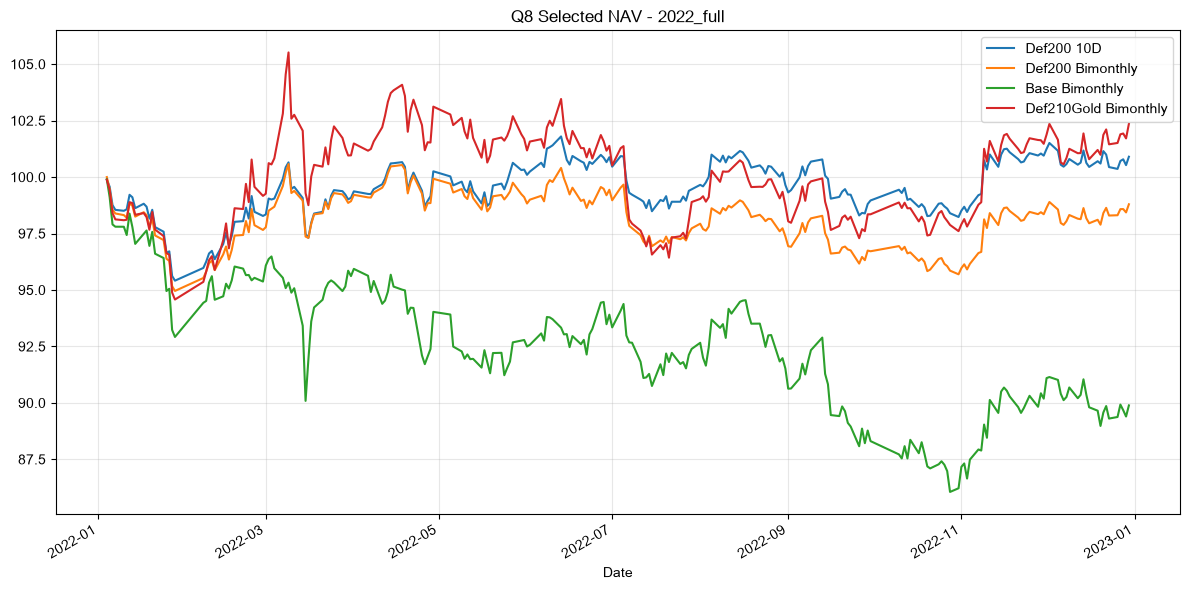

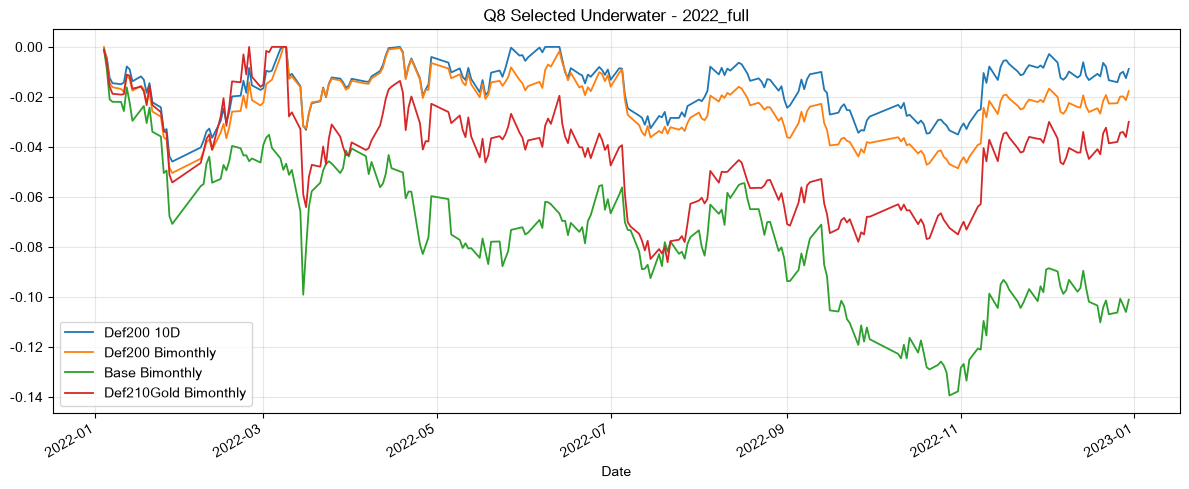

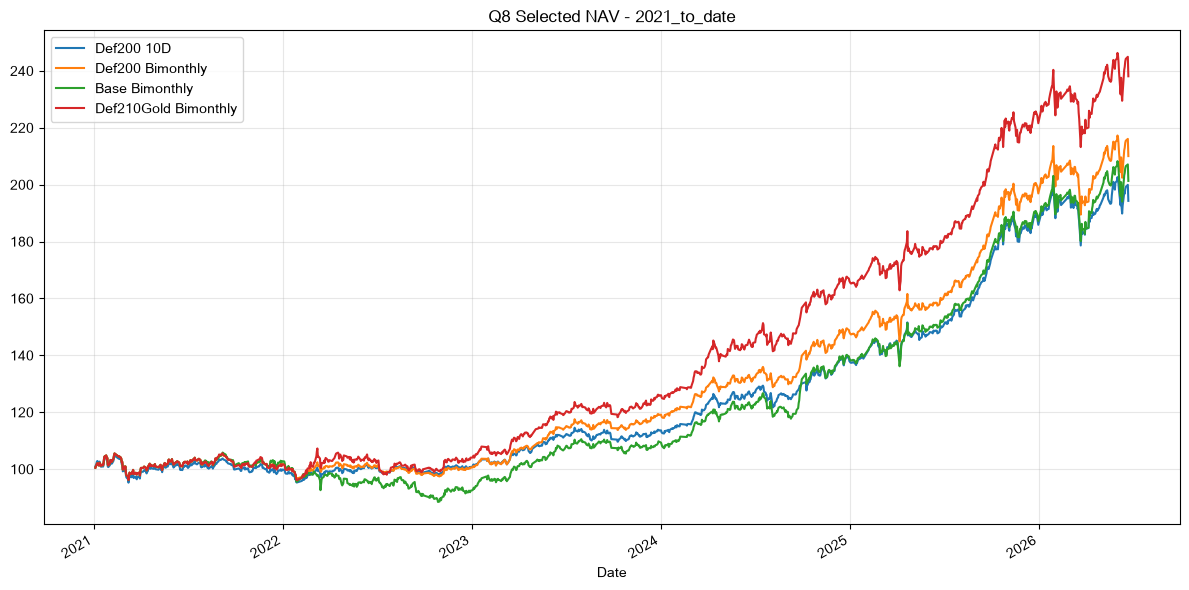

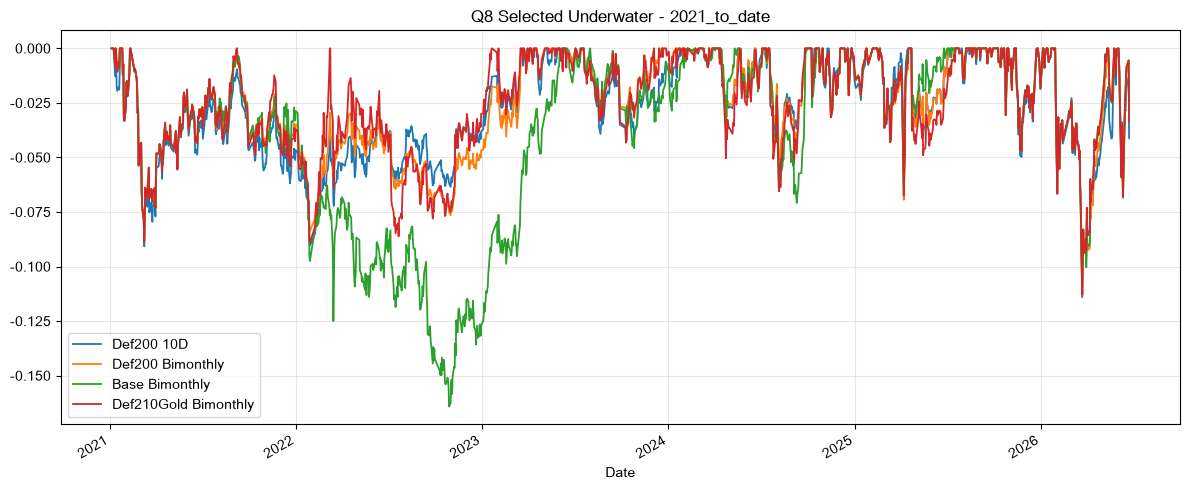

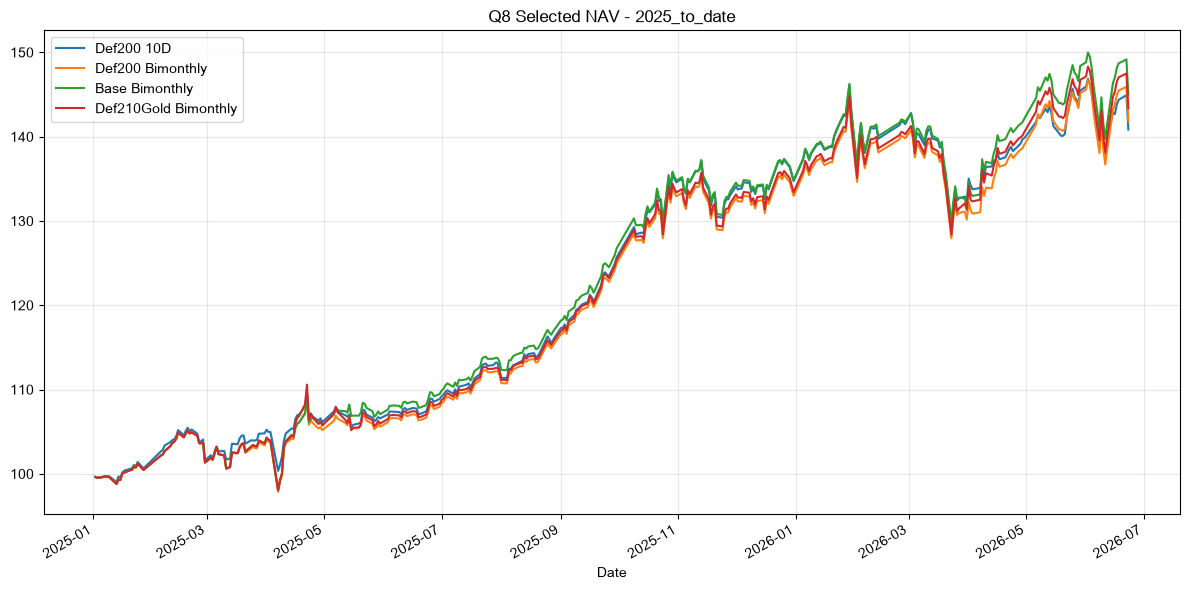

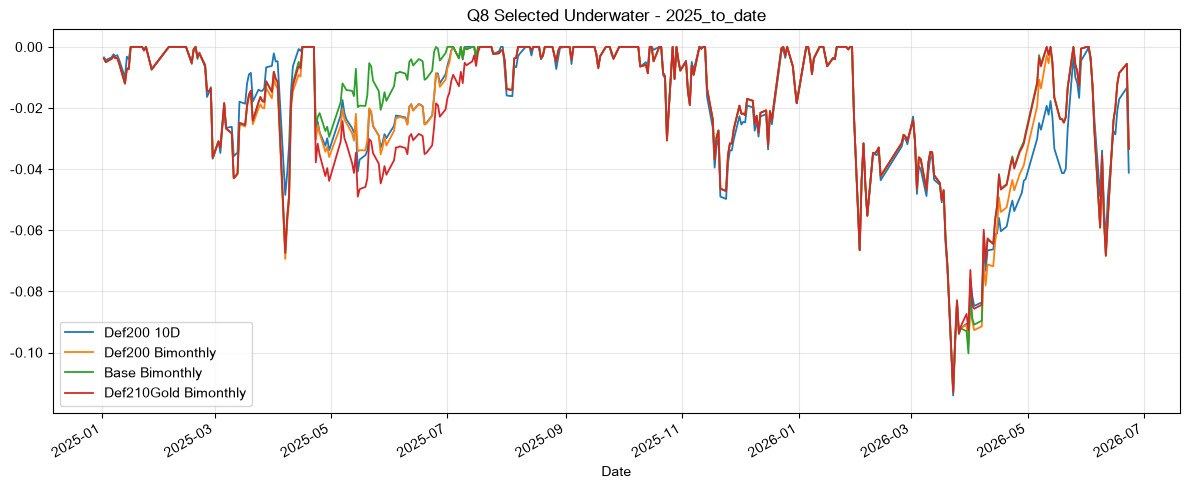

In [8]:
chart_specs = [
    ("Def200_Cash_10D_next_close_base20_plus_asset", "Def200 10D"),
    ("Def200_Cash_BIMONTHLY_next_close_base20_plus_asset", "Def200 Bimonthly"),
    ("Base_Core80_LVT20_BIMONTHLY_next_close_base20_plus_asset", "Base Bimonthly"),
    ("Def210_Gold_BIMONTHLY_next_close_base20_plus_asset", "Def210Gold Bimonthly"),
]
for window, (start, end) in {k: WINDOWS[k] for k in ["2022_full", "2021_to_date", "2025_to_date"]}.items():
    navs = {}
    for name, label in chart_specs:
        r = period_slice(portfolios[name]["returns"], start, end)
        navs[label] = nav_from_returns(r)
    nav_df = pd.DataFrame(navs)
    uw_df = nav_df.apply(drawdown_series)
    nav_df.to_csv(OUTPUT_DIR / f"nav_q8_selected_{window}.csv", encoding="utf-8-sig")
    uw_df.to_csv(OUTPUT_DIR / f"underwater_q8_selected_{window}.csv", encoding="utf-8-sig")
    fig, ax = plt.subplots(figsize=(12, 6))
    nav_df.plot(ax=ax, linewidth=1.5)
    ax.set_title(f"Q8 Selected NAV - {window}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"nav_q8_selected_{window}.png", dpi=160)
    plt.show()
    fig, ax = plt.subplots(figsize=(12, 5))
    uw_df.plot(ax=ax, linewidth=1.3)
    ax.set_title(f"Q8 Selected Underwater - {window}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"underwater_q8_selected_{window}.png", dpi=160)
    plt.show()

## Research Summary

In [9]:
research_summary = all_summary[
    (all_summary["candidate"].isin(["Def200_Cash", "Base_Core80_LVT20", "Def210_Gold"]))
    & (all_summary["schedule"].isin(["10D", "BIMONTHLY"]))
    & (all_summary["execution_mode"] == "next_close")
    & (all_summary["friction_mode"] == "base20_plus_asset")
][["window", "candidate", "schedule", "execution_mode", "friction_mode", "累计收益", "最大回撤", "夏普", "卡玛", "超过-10%天数", "年化成本拖累", "平均现金"]]
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary.round(4))

,window,candidate,schedule,execution_mode,friction_mode,累计收益,最大回撤,夏普,卡玛,超过-10%天数,年化成本拖累,平均现金
4,2021_to_date,Base_Core80_LVT20,10D,next_close,base20_plus_asset,1.0601,-0.1422,1.2282,1.0376,87,0.0168,0.0008
10,2021_to_date,Base_Core80_LVT20,BIMONTHLY,next_close,base20_plus_asset,1.0132,-0.1641,1.1864,0.8686,139,0.0171,0.0027
22,2021_to_date,Def200_Cash,10D,next_close,base20_plus_asset,0.9430,-0.1141,1.2828,1.1825,1,0.0173,0.1607
28,2021_to_date,Def200_Cash,BIMONTHLY,next_close,base20_plus_asset,1.1004,-0.1129,1.4008,1.3445,1,0.0172,0.1622
40,2021_to_date,Def210_Gold,10D,next_close,base20_plus_asset,1.1704,-0.1181,1.3414,1.3471,2,0.0176,0.0083
46,2021_to_date,Def210_Gold,BIMONTHLY,next_close,base20_plus_asset,1.3809,-0.1129,1.4821,1.5909,1,0.0174,0.0056
58,2021_2022_bear,Base_Core80_LVT20,10D,next_close,base20_plus_asset,-0.1406,-0.1422,-0.8101,-0.6207,56,0.0170,0.0002
64,2021_2022_bear,Base_Core80_LVT20,BIMONTHLY,next_close,base20_plus_asset,-0.1600,-0.1641,-0.9264,-0.6147,84,0.0180,0.0066
76,2021_2022_bear,Def200_Cash,10D,next_close,base20_plus_asset,-0.0635,-0.0907,-0.4671,-0.4323,0,0.0159,0.2448
82,2021_2022_bear,Def200_Cash,BIMONTHLY,next_close,base20_plus_asset,-0.0765,-0.0884,-0.5706,-0.5361,0,0.0165,0.2523
